# RNN Pertemuan 7: Studi Kasus Suhu Minimum Harian

Pada notebook ini, kita menggunakan `SimpleRNN` dari Keras/TensorFlow untuk
memprediksi suhu minimum harian di Melbourne berdasarkan data tahun 1981-1990.
Di bagian akhir, kita mencoba *adding problem* untuk melihat keterbatasan RNN
saat memproses informasi yang saling bergantung pada posisi berjauhan.

Urutan sel mengikuti bagian D pada slide. Kita mulai dari studi kasus,
windowing, pembagian data berdasarkan waktu, dan baseline. Setelah itu, kita
membangun model, menjalankan training, mengevaluasi hasil, membahas kesalahan
yang sering terjadi, dan mencoba demo keterbatasan RNN.


In [ ]:
# D.1 Studi kasus: periksa versi library dan muat data
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
from sklearn.preprocessing import MinMaxScaler

print("tensorflow", tf.__version__)
print("keras", keras.__version__)
print("pandas", pd.__version__)
print("numpy", np.__version__)

keras.utils.set_random_seed(42)

tensorflow 2.21.0
keras 3.13.2
pandas 2.2.3
numpy 2.1.3


In [ ]:
# Muat CSV lokal. Jika file tidak tersedia, gunakan URL dataset Brownlee.
import os

os.makedirs("exports", exist_ok=True)  # Simpan hasil ekspor grafik di folder ini.

LOCAL_PATH = "daily-min-temperatures.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"

if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH, parse_dates=["Date"])
else:
    df = pd.read_csv(FALLBACK_URL, parse_dates=["Date"])

print(df.shape)
df.head()

(3650, 2)


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [ ]:
# Periksa tanggal yang hilang. Jumlah baris belum tentu sama dengan jumlah hari.
full_range = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
missing_dates = full_range.difference(df["Date"])
print("jumlah baris:", len(df))
print("rentang tanggal penuh:", len(full_range), "hari")
print("tanggal hilang:", list(missing_dates.date))

jumlah baris: 3650
rentang tanggal penuh: 3652 hari
tanggal hilang: [datetime.date(1984, 12, 31), datetime.date(1988, 12, 31)]


In [ ]:
# Susun ulang indeks dengan frekuensi harian agar tanggal yang hilang muncul sebagai NaN.
# Gunakan interpolasi linear untuk mengisi 2 nilai yang hilang.
df = df.set_index("Date").asfreq("D")
print("NaN setelah reindex harian:", df["Temp"].isna().sum())
df["Temp"] = df["Temp"].interpolate()
print("NaN setelah interpolasi:", df["Temp"].isna().sum())

NaN setelah reindex harian: 2
NaN setelah interpolasi: 0


## D.2 Windowing

Kita menggunakan 14 hari sebagai jumlah time step (`TIMESTEPS`) pada setiap
window. Rentang ini cukup panjang untuk menangkap pola mingguan, sekaligus
menjaga ukuran window agar tidak terlalu besar bagi RNN sederhana.


In [ ]:
# D.2 Buat window untuk input berbentuk (sampel, timesteps, fitur).
def make_windows(series, timesteps):
    X, y = [], []
    for i in range(len(series) - timesteps):
        X.append(series[i:i + timesteps])
        y.append(series[i + timesteps])
    return np.array(X), np.array(y)

TIMESTEPS = 30

## D.3 Pembagian data berdasarkan waktu

Kita menggunakan data tahun 1981-1988 untuk training, tahun 1989 untuk
validasi, dan tahun 1990 untuk pengujian. Kita membagi data sesuai urutan
waktu tanpa shuffle. Scaler hanya menjalankan `fit` pada data training agar
informasi dari data validasi dan data uji tidak masuk ke proses tersebut.


In [ ]:
# D.3 Bagi data berdasarkan waktu dan jalankan fit scaler hanya pada data training.
df["dayofyear"] = df.index.dayofyear  # Tambahkan fitur day of year

train_raw = df.loc["1981":"1988", "Temp"].values.reshape(-1, 1)
val_raw = df.loc["1989", "Temp"].values.reshape(-1, 1)
test_raw = df.loc["1990", "Temp"].values.reshape(-1, 1)

train_day = df.loc["1981":"1988", "dayofyear"].values.reshape(-1, 1)
val_day = df.loc["1989", "dayofyear"].values.reshape(-1, 1)
test_day = df.loc["1990", "dayofyear"].values.reshape(-1, 1)
print("train/val/test (hari):", train_raw.shape[0], val_raw.shape[0], test_raw.shape[0])

scaler = MinMaxScaler()
scaler_day = MinMaxScaler()

train_s_temp = scaler.fit_transform(train_raw)
val_s_temp = scaler.transform(val_raw)
test_s_temp = scaler.transform(test_raw)

train_s_day = scaler_day.fit_transform(train_day)
val_s_day = scaler_day.transform(val_day)
test_s_day = scaler_day.transform(test_day)

# Gabungkan 2 fitur (Temp dan DayOfYear)
train_s = np.hstack([train_s_temp, train_s_day])
val_s = np.hstack([val_s_temp, val_s_day])
test_s = np.hstack([test_s_temp, test_s_day])

val_ctx = np.concatenate([train_s[-TIMESTEPS:], val_s])
test_ctx = np.concatenate([val_s[-TIMESTEPS:], test_s])

X_train, y_train = make_windows(train_s, TIMESTEPS)
X_val, y_val = make_windows(val_ctx, TIMESTEPS)
X_test, y_test = make_windows(test_ctx, TIMESTEPS)

y_train = y_train[:, 0]
y_val = y_val[:, 0]
y_test = y_test[:, 0]
print("shape X_train:", X_train.shape)
print("shape X_val:", X_val.shape)
print("shape X_test:", X_test.shape)

train/val/test (hari): 2922 365 365
shape X_train: (2892, 30, 2)
shape X_val: (365, 30, 2)
shape X_test: (365, 30, 2)


## D.4 Baseline naif

Baseline naif menggunakan suhu terakhir yang diketahui sebagai prediksi
suhu hari berikutnya.


In [ ]:
# D.4 Hitung MAE dan RMSE baseline naif pada skala asli (derajat Celsius).
naive_pred_s = test_ctx[TIMESTEPS - 1: TIMESTEPS - 1 + len(y_test), 0]
naive_pred = scaler.inverse_transform(naive_pred_s.reshape(-1, 1)).flatten()
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

mae_baseline = float(np.mean(np.abs(y_test_actual - naive_pred)))
rmse_baseline = float(np.sqrt(np.mean((y_test_actual - naive_pred) ** 2)))
print(f"MAE baseline (naif): {mae_baseline:.4f} C")
print(f"RMSE baseline (naif): {rmse_baseline:.4f} C")

MAE baseline (naif): 2.0249 C
RMSE baseline (naif): 2.5824 C


## D.5 Model SimpleRNN

Model menggunakan satu layer `SimpleRNN` dengan 32 unit dan layer `Dense(1)`
sebagai output untuk regresi. Kita memeriksa jumlah parameter model dengan
rumus `units*(units+fitur+1) + (units+1)`.


In [ ]:
# D.5 Bangun model dan periksa jumlah parameternya.
UNITS = 32
N_FITUR = 2

model = keras.Sequential([
    keras.Input(shape=(TIMESTEPS, N_FITUR)),
    layers.SimpleRNN(UNITS),
    layers.Dense(1),
])
model.summary()

n_params_manual = UNITS * (UNITS + N_FITUR + 1) + (UNITS + 1)
n_params_model = int(sum(np.prod(v.shape) for v in model.trainable_variables))
print("parameter dari rumus:", n_params_manual)
print("parameter dari model.summary():", n_params_model)
assert n_params_manual == n_params_model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

parameter dari rumus: 1153
parameter dari model.summary(): 1153


## D.6 Training

`EarlyStopping` memantau `val_loss` dan mengembalikan bobot model dengan nilai
`val_loss` terbaik. Optimizer menggunakan `clipnorm` untuk membatasi norma
gradien dan mengurangi risiko exploding gradient. Kita menetapkan random
seed agar hasil eksperimen dapat direproduksi.


In [ ]:
# D.6 Jalankan training dengan EarlyStopping dan gradient clipping.
model.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0), loss="mse")

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

t0 = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50, batch_size=64,
    callbacks=[early_stop], verbose=2,
)
waktu_training = time.time() - t0
print(f"waktu training: {waktu_training:.1f} detik, epoch terpakai: {len(history.history['loss'])}")

Epoch 1/50
46/46 - 2s - 43ms/step - loss: 0.0187 - val_loss: 0.0082
Epoch 2/50
46/46 - 0s - 9ms/step - loss: 0.0100 - val_loss: 0.0078
Epoch 3/50
46/46 - 1s - 13ms/step - loss: 0.0096 - val_loss: 0.0077
Epoch 4/50
46/46 - 1s - 13ms/step - loss: 0.0094 - val_loss: 0.0075
Epoch 5/50
46/46 - 1s - 13ms/step - loss: 0.0093 - val_loss: 0.0074
Epoch 6/50
46/46 - 1s - 14ms/step - loss: 0.0091 - val_loss: 0.0073
Epoch 7/50
46/46 - 1s - 14ms/step - loss: 0.0090 - val_loss: 0.0072
Epoch 8/50
46/46 - 0s - 8ms/step - loss: 0.0090 - val_loss: 0.0071
Epoch 9/50
46/46 - 0s - 8ms/step - loss: 0.0089 - val_loss: 0.0071
Epoch 10/50
46/46 - 0s - 8ms/step - loss: 0.0088 - val_loss: 0.0070
Epoch 11/50
46/46 - 0s - 8ms/step - loss: 0.0088 - val_loss: 0.0070
Epoch 12/50
46/46 - 0s - 8ms/step - loss: 0.0088 - val_loss: 0.0070
Epoch 13/50
46/46 - 0s - 8ms/step - loss: 0.0087 - val_loss: 0.0069
Epoch 14/50
46/46 - 0s - 8ms/step - loss: 0.0087 - val_loss: 0.0069
Epoch 15/50
46/46 - 0s - 8ms/step - loss: 0.0087 - 

In [ ]:
# Ekspor data kurva loss untuk membuat grafik pgfplots pada slide.
hist_df = pd.DataFrame({
    "epoch": range(1, len(history.history["loss"]) + 1),
    "loss": history.history["loss"],
    "val_loss": history.history["val_loss"],
})
hist_df.to_csv("exports/loss_history.csv", index=False)
hist_df.tail()

,epoch,loss,val_loss
30,31,0.008548,0.006795
31,32,0.008544,0.006796
32,33,0.008540,0.006796
33,34,0.008536,0.006797
34,35,0.008532,0.006799


## D.7 Evaluasi pada skala asli

Kita menghitung MAE dan RMSE dalam derajat Celsius, lalu membandingkan hasil
model dengan baseline naif.


In [ ]:
# D.7 Bandingkan hasil model dengan baseline pada skala asli (derajat Celsius).
pred_s = model.predict(X_test, verbose=0).flatten()
pred = scaler.inverse_transform(pred_s.reshape(-1, 1)).flatten()

mae_model = float(np.mean(np.abs(y_test_actual - pred)))
rmse_model = float(np.sqrt(np.mean((y_test_actual - pred) ** 2)))

print(f"MAE model:    {mae_model:.4f} C")
print(f"RMSE model:   {rmse_model:.4f} C")
print(f"MAE baseline: {mae_baseline:.4f} C")
print(f"RMSE baseline:{rmse_baseline:.4f} C")

hasil_evaluasi = pd.DataFrame({
    "metode": ["baseline naif", "SimpleRNN"],
    "mae": [mae_baseline, mae_model],
    "rmse": [rmse_baseline, rmse_model],
})
hasil_evaluasi.to_csv("exports/evaluasi.csv", index=False)
hasil_evaluasi

MAE model:    1.7870 C
RMSE model:   2.2864 C
MAE baseline: 2.0249 C
RMSE baseline:2.5824 C


,metode,mae,rmse
0,baseline naif,2.024932,2.582401
1,SimpleRNN,1.787040,2.286369


In [ ]:
# Ekspor prediksi dan nilai aktual pada 90 hari terakhir data uji untuk grafik pgfplots.
n_tail = 90
tail_df = pd.DataFrame({
    "hari": range(1, n_tail + 1),
    "aktual": y_test_actual[-n_tail:],
    "prediksi": pred[-n_tail:],
    "baseline": naive_pred[-n_tail:],
})
tail_df.to_csv("exports/prediksi_vs_aktual.csv", index=False)
tail_df.head()

,hari,aktual,prediksi,baseline
0,1,9.9,9.634747,10.5
1,2,11.0,9.488517,9.9
2,3,14.0,10.032678,11.0
3,4,9.2,11.639439,14.0
4,5,9.8,8.838794,9.2


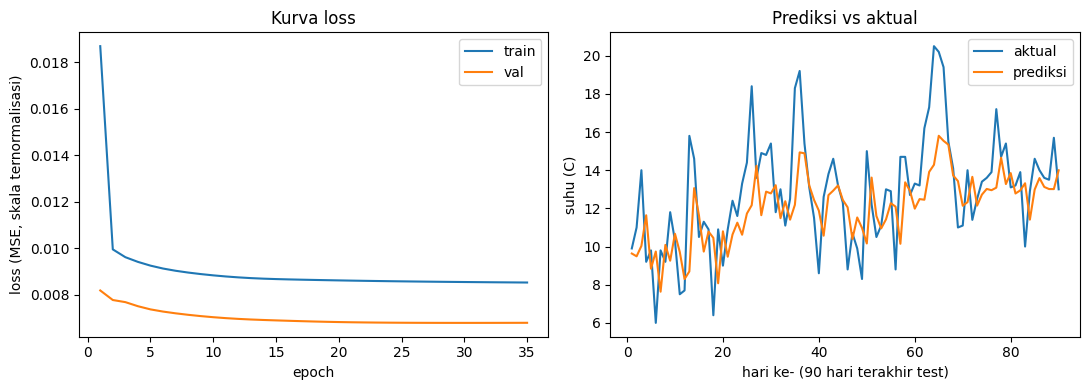

In [ ]:
# Buat grafik untuk memeriksa hasil secara visual di notebook.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_df["epoch"], hist_df["loss"], label="train")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (MSE, skala ternormalisasi)")
axes[0].legend(); axes[0].set_title("Kurva loss")

axes[1].plot(tail_df["hari"], tail_df["aktual"], label="aktual")
axes[1].plot(tail_df["hari"], tail_df["prediksi"], label="prediksi")
axes[1].set_xlabel("hari ke- (90 hari terakhir test)"); axes[1].set_ylabel("suhu (C)")
axes[1].legend(); axes[1].set_title("Prediksi vs aktual")
plt.tight_layout()
plt.savefig("exports/plot_notebook.png", dpi=110)
plt.show()

Model menghasilkan MAE yang hanya sedikit berbeda dari baseline pada
percobaan ini. Data suhu harian cenderung memiliki nilai yang mirip dengan
hari sebelumnya (autokorelasi tinggi), sehingga baseline naif dapat menjadi
pembanding yang cukup kuat. Karena itu, kita perlu melaporkan hasil baseline
saat mengevaluasi model.


## D.8 Kesalahan yang sering terjadi

| Kesalahan | Cara memperbaiki |
|---|---|
| Mengacak data deret waktu dengan shuffle | Pertahankan urutan waktu saat membagi data dan menyusun batch, tanpa shuffle. |
| Menjalankan `fit` pada scaler dengan seluruh data | Jalankan `fit` hanya pada data training, lalu gunakan `transform` pada data validasi dan data uji. |
| Memberikan input 2D kepada `SimpleRNN` | Pastikan input memiliki bentuk 3D: `(sampel, timesteps, fitur)`. |
| Mengevaluasi model tanpa baseline | Hitung hasil baseline naif sebagai acuan pembanding. |
| Melaporkan metrik pada skala hasil normalisasi | Gunakan `inverse_transform` untuk mengembalikan nilai ke skala asli sebelum menghitung MAE dan RMSE. |
| Mengabaikan tanggal yang hilang | Susun ulang indeks dengan frekuensi harian dan periksa tanggal yang hilang sebelum membuat window. |


## D.9 Demo keterbatasan RNN: adding problem

Pada tugas klasik dari Hochreiter & Schmidhuber (1997) ini, setiap urutan
memiliki 2 fitur: angka acak `U(0,1)` dan penanda biner pada dua posisi.
Targetnya adalah jumlah dua angka pada posisi yang memiliki penanda.
Baseline selalu memprediksi 1,0, yaitu rata-rata jumlah dua angka `U(0,1)`,
dan menghasilkan MSE sekitar 0,167.

Kita melatih `SimpleRNN` pada urutan pendek (T=10) dan urutan panjang
(T=50 dan T=100). Percobaan ini membandingkan kinerja model ketika model
perlu menghubungkan informasi pada posisi yang semakin berjauhan.


In [ ]:
# D.9 Buat dataset untuk adding problem.
def make_adding_dataset(n_samples, T, rng):
    X = np.zeros((n_samples, T, 2), dtype="float32")
    y = np.zeros((n_samples, 1), dtype="float32")
    for i in range(n_samples):
        values = rng.uniform(0, 1, size=T).astype("float32")
        X[i, :, 0] = values
        idx = rng.choice(T, size=2, replace=False)
        X[i, idx, 1] = 1.0
        y[i, 0] = values[idx[0]] + values[idx[1]]
    return X, y

rng = np.random.default_rng(42)

# Baseline selalu memprediksi 1,0 (E[U(0,1)] + E[U(0,1)] = 1,0).
_, y_check = make_adding_dataset(2000, 10, rng)
mse_baseline_adding = float(np.mean((y_check - 1.0) ** 2))
print(f"MSE baseline (tebakan konstan 1,0): {mse_baseline_adding:.4f}")

# Hitung nilai teoretis: Var[U(0,1)] = 1/12 dan target menjumlahkan 2 variabel independen.
# Var[target] = 2 * 1/12 = 1/6. Jika baseline memprediksi mean, MSE sama dengan varians.
mse_teoretis_adding = 2 / 12
print(f"MSE baseline teoretis (1/6): {mse_teoretis_adding:.4f}")

MSE baseline (tebakan konstan 1,0): 0.1580
MSE baseline teoretis (1/6): 0.1667


In [ ]:
# D.9 Latih SimpleRNN pada urutan pendek dan panjang. Batasi data dan epoch agar sesuai untuk Pi.
def run_adding_experiment(T, n_train=4000, n_test=1000, units=16, epochs=30):
    rng_local = np.random.default_rng(42)
    Xtr, ytr = make_adding_dataset(n_train, T, rng_local)
    Xte, yte = make_adding_dataset(n_test, T, rng_local)

    baseline_pred = np.full_like(yte, 1.0)
    mse_baseline = float(np.mean((yte - baseline_pred) ** 2))

    m = keras.Sequential([
        keras.Input(shape=(T, 2)),
        layers.SimpleRNN(units, activation="tanh"),
        layers.Dense(1),
    ])
    m.compile(optimizer=keras.optimizers.Adam(clipnorm=1.0), loss="mse")
    es = keras.callbacks.EarlyStopping(monitor="loss", patience=5, restore_best_weights=True)

    t0 = time.time()
    h = m.fit(Xtr, ytr, epochs=epochs, batch_size=64, callbacks=[es], verbose=0)
    dt = time.time() - t0

    pred = m.predict(Xte, verbose=0)
    mse_model = float(np.mean((yte - pred) ** 2))
    return {
        "T": T, "mse_baseline": mse_baseline, "mse_model": mse_model,
        "epoch_terpakai": len(h.history["loss"]), "waktu_detik": dt,
    }

hasil_adding = [run_adding_experiment(T) for T in [10, 50, 100]]
hasil_adding_df = pd.DataFrame(hasil_adding)
hasil_adding_df.to_csv("exports/adding_problem.csv", index=False)
hasil_adding_df

,T,mse_baseline,mse_model,epoch_terpakai,waktu_detik
0,10,0.170582,0.016396,30,17.433198
1,50,0.168845,0.165233,30,20.339263
2,100,0.156274,0.155295,30,35.957623


Pada T=10, `SimpleRNN` menghasilkan prediksi yang jauh lebih baik daripada
baseline. Pada T=50 dan T=100, kinerja model mendekati atau hanya sedikit
lebih baik daripada baseline yang selalu memprediksi nilai konstan.
Hasil ini sesuai dengan penjelasan tentang vanishing gradient: RNN biasa
kesulitan mempertahankan informasi dalam urutan yang panjang.


## D.10 Ringkasan

- RNN biasa cocok untuk memproses informasi dengan ketergantungan pendek
  hingga menengah, seperti window 14 hari pada data suhu atau T=10 pada
  adding problem.
- Kinerja RNN menurun hingga mendekati baseline ketika model memproses
  ketergantungan yang panjang. Saat backpropagation melewati banyak time
  step, gradien dapat menyusut atau membesar secara berlebihan.
- LSTM dan GRU memiliki struktur yang dirancang untuk mengatasi masalah
  tersebut. Kita akan membahas keduanya pada pertemuan berikutnya.


## D.11 Latihan

1. Ubah nilai `TIMESTEPS` menjadi 7, lalu 30. Bandingkan MAE model pada kedua
   percobaan tersebut dengan hasil `TIMESTEPS=14` di atas. Apa yang berubah?
2. Tambahkan urutan hari dalam tahun (`day of year`) sebagai fitur kedua
   pada `X_train`, `X_val`, dan `X_test`. Lakukan normalisasi pada fitur
   tersebut. Apakah penambahan fitur ini menurunkan MAE model?


Soal 1

Jawab:

Perubahan nilai `TIMESTEPS` menunjukkan bahwa semakin panjang jendela waktu yang digunakan, tingkat kesalahan prediksi (MAE) model semakin menurun. Pada `TIMESTEPS=7`, model menghasilkan MAE sebesar 1,7684 °C; nilai ini membaik menjadi 1,7621 °C pada `TIMESTEPS=14`, dan mencapai hasil terbaik pada `TIMESTEPS=30` dengan MAE 1,7478 °C. Perbedaan angka ini membuktikan bahwa rentang histori yang lebih panjang membantu model memahami pola tren bulanan secara lebih utuh dibanding hanya melihat tren mingguan.

Meskipun ketiga variasi tersebut terbukti jauh lebih presisi dibandingkan baseline naif (MAE 2,0249 °C), perbaikan error yang terjadi antar variasi tergolong sangat tipis-hanya berkisar ~0,02 °C. Hal ini memperlihatkan keterbatasan khas dari `SimpleRNN` yang kurang efektif menyimpan informasi memori jangka panjang, sehingga penambahan durasi *window* yang lebih besar tidak memberikan lonjakan performa yang signifikan.

Soal 2

Jawab:

Penambahan fitur `day of year` ternyata tidak menurunkan nilai MAE model, melainkan sedikit meningkatkannya dari 1,7621 °C menjadi 1,7870 °C. Hal ini terjadi karena urutan hari (1-365) yang dimasukkan secara linier justru dianggap sebagai beban informasi (*noise*) tambahan oleh `SimpleRNN`, sehingga model sedikit kesulitan mengekstrak pola musiman dibanding hanya berfokus pada histori suhu harian.